Dataset Loaded. Total X-rays: 223414


/tmp/ipykernel_57/3130347567.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=disease_counts.values, y=disease_counts.index, palette='viridis')


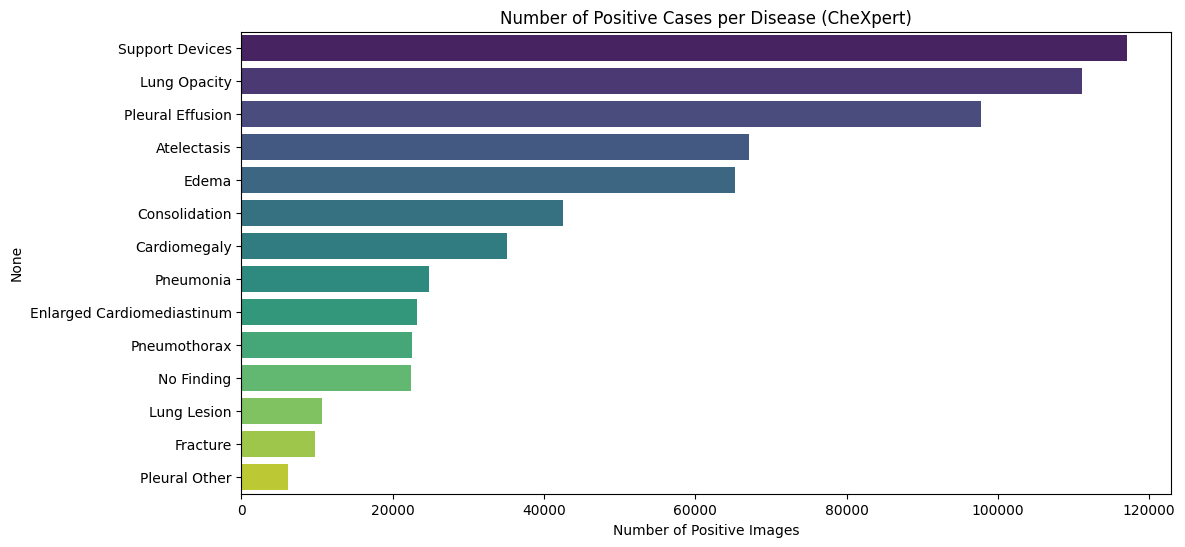


--- EXACT DISEASE COUNTS ---
Support Devices               117080.0
Lung Opacity                  111179.0
Pleural Effusion               97815.0
Atelectasis                    67115.0
Edema                          65230.0
Consolidation                  42525.0
Cardiomegaly                   35087.0
Pneumonia                      24809.0
Enlarged Cardiomediastinum     23201.0
Pneumothorax                   22593.0
No Finding                     22381.0
Lung Lesion                    10674.0
Fracture                        9682.0
Pleural Other                   6176.0
dtype: float64

--- IMBALANCE RATIO (Negatives : 1 Positive) ---
Support Devices           : 1 positive for every 0.9 negatives
Lung Opacity              : 1 positive for every 1.0 negatives
Pleural Effusion          : 1 positive for every 1.3 negatives
Atelectasis               : 1 positive for every 2.3 negatives
Edema                     : 1 positive for every 2.4 negatives
Consolidation             : 1 positive for e

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

# 1. Load the dataset
csv_path = '/kaggle/input/datasets/ashery/chexpert/train.csv' 
df = pd.read_csv(csv_path)

print(f"Dataset Loaded. Total X-rays: {len(df)}")

# 2. the 14 Pathologies 
all_diseases = [
    'No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 
    'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 
    'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices'
]

# 3. Clean  Data for Analysis
# 
#   NaN -> 0 (Negative)
#   -1  -> 1 (Positive)  <-- This is the "U-Ones" strategy (aggressive)
clean_df = df.copy()
for disease in all_diseases:
    clean_df[disease] = clean_df[disease].fillna(0)  # NaNs become 0
    clean_df[disease] = clean_df[disease].abs()      # -1s become 1

# 4. Calculate the Counts
# We sum the columns to see how many '1's exist for each disease
disease_counts = clean_df[all_diseases].sum().sort_values(ascending=False)

# 5. Visualize the Imbalance
plt.figure(figsize=(12, 6))
sns.barplot(x=disease_counts.values, y=disease_counts.index, palette='viridis')
plt.title('Number of Positive Cases per Disease (CheXpert)')
plt.xlabel('Number of Positive Images')
plt.show()

# 6. Print the exact numbers (Crucial for Weights later)
print("\n--- EXACT DISEASE COUNTS ---")
print(disease_counts)

# 7. Check the "Imbalance Ratio"
print("\n--- IMBALANCE RATIO (Negatives : 1 Positive) ---")
total_images = len(clean_df)
for disease, count in disease_counts.items():
    ratio = (total_images - count) / count
    print(f"{disease:25} : 1 positive for every {ratio:.1f} negatives")

In [2]:
import torch
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd # Ensure pandas is imported in this cell if run independently

# --- 1. SETUP & LOADING ---
csv_path = '/kaggle/input/datasets/ashery/chexpert/train.csv'
root_dir = '/kaggle/input/datasets/ashery/chexpert' 

print(f"Loading dataset from: {csv_path}")
df = pd.read_csv(csv_path)

# --- 2. PATH ENGINEERING ---
print("Fixing image paths to match local environment...")
df['Path'] = df['Path'].str.replace('CheXpert-v1.0-small', root_dir, regex=False)

# --- 3. FILTER & CLEAN ---
df = df[df['Frontal/Lateral'] == 'Frontal']
df = df.fillna(0)

target_cols = ['No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 
               'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 
               'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']
df[target_cols] = df[target_cols].replace(-1, 1)

# --- 4. THE ENGINEERED SPLIT ---
# FIX: Use regex to safely extract the patient ID regardless of folder depth
df['patient_id'] = df['Path'].str.extract(r'(patient\d+)')[0]

# Split 90% Train, 10% Valid (Grouped by Patient)
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df['patient_id']))

# Create the clean dataframes
train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print(f"[SUCCESS] Split Complete.")
print(f"Training on {len(train_df)} images.")
print(f"Validating on {len(val_df)} images (Unique Patients).")

# --- 5. RE-CALCULATE WEIGHTS ---
pos_weights = []
print("\n--- RE-CALCULATED WEIGHTS (Training Set Only) ---")
for col in target_cols:
    n_pos = train_df[col].sum()
    n_neg = len(train_df) - n_pos
    
    if n_pos == 0:
        weight = 1.0
    else:
        weight = n_neg / n_pos
    
    pos_weights.append(weight)
    print(f"{col:<25} : {weight:.2f}x")

pos_weight_tensor = torch.tensor(pos_weights, dtype=torch.float32)

print("\n[READY] train_df, val_df, and pos_weight_tensor are ready.")

Loading dataset from: /kaggle/input/datasets/ashery/chexpert/train.csv
Fixing image paths to match local environment...
[SUCCESS] Split Complete.
Training on 171927 images.
Validating on 19100 images (Unique Patients).

--- RE-CALCULATED WEIGHTS (Training Set Only) ---
No Finding                : 10.30x
Enlarged Cardiomediastinum : 8.79x
Cardiomegaly              : 5.36x
Lung Opacity              : 0.94x
Lung Lesion               : 22.35x
Edema                     : 2.10x
Consolidation             : 4.12x
Pneumonia                 : 8.22x
Atelectasis               : 2.21x
Pneumothorax              : 8.39x
Pleural Effusion          : 1.21x
Pleural Other             : 43.62x
Fracture                  : 23.11x
Support Devices           : 0.76x

[READY] train_df, val_df, and pos_weight_tensor are ready.


In [3]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import functional as F
from PIL import Image

# --- 1. CUSTOM SQUARE PAD CLASS (The Engineering Fix) ---
class SquarePad:
    def __call__(self, image):
        w, h = image.size
        max_wh = max(w, h)
        p_left, p_top = (max_wh - w) // 2, (max_wh - h) // 2
        p_right, p_bottom = max_wh - w - p_left, max_wh - h - p_top
        padding = (p_left, p_top, p_right, p_bottom)
        return F.pad(image, padding, 0, 'constant')

# --- 2. DEFINE TRANSFORMS (With Padding) ---
# We add SquarePad() BEFORE Resizing.
# This ensures the image becomes a square (with black bars) FIRST,
# so the Resize step doesn't distort the anatomy.

train_transform = transforms.Compose([
    SquarePad(),                      # Step 1: Make it square (preserve shape)
    transforms.Resize((224, 224)),    # Step 2: Scale down
    transforms.RandomAffine(degrees=10, translate=(0.02, 0.02), scale=(0.98, 1.02)), # Augmentation
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    SquarePad(),                      # Step 1: Make it square
    transforms.Resize((224, 224)),    # Step 2: Scale down
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# --- 3. DATASET CLASS (Unchanged) ---
class CheXpertDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform
        self.target_cols = ['No Finding', 'Enlarged Cardiomediastinum', 'Cardiomegaly', 'Lung Opacity', 
                            'Lung Lesion', 'Edema', 'Consolidation', 'Pneumonia', 'Atelectasis', 
                            'Pneumothorax', 'Pleural Effusion', 'Pleural Other', 'Fracture', 'Support Devices']
        
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        img_path = row['Path']
        labels = torch.tensor(row[self.target_cols].values.astype('float32'))
        
        try:
            image = Image.open(img_path).convert("RGB")
        except FileNotFoundError:
            image = Image.new('RGB', (224, 224))
            
        if self.transform:
            image = self.transform(image)
            
        return image, labels

# --- 4. CREATE LOADERS ---
BATCH_SIZE = 32 

train_dataset = CheXpertDataset(train_df, transform=train_transform)
val_dataset = CheXpertDataset(val_df, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"[SUCCESS] DataLoaders updated with Aspect Ratio Preservation (Padding).")

[SUCCESS] DataLoaders updated with Aspect Ratio Preservation (Padding).


In [4]:
# --- 4. SANITY CHECK (Visual Audit) ---
data_iter = iter(train_loader)
images, labels = next(data_iter)

print("\n--- BATCH AUDIT ---")
print(f"Image Tensor Shape: {images.shape} (Should be [32, 3, 224, 224])")
print(f"Label Tensor Shape: {labels.shape} (Should be [32, 14])")
print(f"Min Pixel Value: {images.min():.3f} (Should be negative due to normalization)")
print(f"Max Pixel Value: {images.max():.3f}")

# Check the first sample in the batch
print("\nSample Labels (First Image in Batch):")
sample_labels = labels[0]
for i, col in enumerate(target_cols):
    if sample_labels[i] == 1:
        print(f" - {col} (POSITIVE)")


--- BATCH AUDIT ---
Image Tensor Shape: torch.Size([32, 3, 224, 224]) (Should be [32, 3, 224, 224])
Label Tensor Shape: torch.Size([32, 14]) (Should be [32, 14])
Min Pixel Value: -2.118 (Should be negative due to normalization)
Max Pixel Value: 2.640

Sample Labels (First Image in Batch):
 - Cardiomegaly (POSITIVE)


In [5]:
import random
import os



# --- 1. LOCK RANDOM SEEDS (Scientific Reproducibility) ---
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False 

seed_everything(42)
print("[SUCCESS] Random seeds locked. Your results will now be reproducible.")

# --- 2. CHECK METRICS LIBRARY ---
# 'torchmetrics' or 'scikit-learn' for AUROC.

try:
    from sklearn.metrics import roc_auc_score
    print("[SUCCESS] Scikit-learn is ready for AUROC calculation.")
except ImportError:
    print("[INSTALLING] Scikit-learn not found. Installing...")
    !pip install -q scikit-learn
    from sklearn.metrics import roc_auc_score

[SUCCESS] Random seeds locked. Your results will now be reproducible.
[SUCCESS] Scikit-learn is ready for AUROC calculation.


In [6]:

from torch.utils.data import DataLoader
import copy

# --- CONFIGURATION ---
NUM_CLIENTS = 3  # Simulating 3 Hospitals
BATCH_SIZE = 32

print(f"Partitioning data among {NUM_CLIENTS} simulated clients...")

# 1. Get unique patients
unique_patients = train_df['patient_id'].unique()
# Shuffle them to ensure random distribution
np.random.shuffle(unique_patients)

# 2. Split patients into 3 chunks
patient_splits = np.array_split(unique_patients, NUM_CLIENTS)

# 3. Create DataLoaders for each Client
client_loaders = []
client_data_sizes = []

for i, patients in enumerate(patient_splits):
    # Filter the main dataframe for this client's patients
    client_df = train_df[train_df['patient_id'].isin(patients)].reset_index(drop=True)
    
    # Create a local dataset for this client
    # Note: We use the SAME transform (SquarePad) we built earlier
    client_dataset = CheXpertDataset(client_df, transform=train_transform)
    
    # Create the loader
    loader = DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    
    client_loaders.append(loader)
    client_data_sizes.append(len(client_df))
    
    print(f"Client {i+1} (Hospital {chr(65+i)}): {len(client_df)} images")

print(f"[SUCCESS] Federated Data Partitioning Complete.")

Partitioning data among 3 simulated clients...
Client 1 (Hospital A): 56648 images
Client 2 (Hospital B): 57610 images
Client 3 (Hospital C): 57669 images
[SUCCESS] Federated Data Partitioning Complete.


In [7]:
def federated_average(global_weights, local_weights_list, client_sizes):
    """
    Performs FedAvg: Weighted average of local models.
    """
    # Create a copy of the global weights to store the average
    avg_weights = copy.deepcopy(global_weights)
    
    total_data_points = sum(client_sizes)
    
    # Iterate through every layer in the model 
    for key in avg_weights.keys():
        weighted_sum = 0
        
        for i, local_weights in enumerate(local_weights_list):
            n_k = client_sizes[i] # Number of images this client has
            
            # Weighted contribution: (Weight * ClientSize)
            weighted_sum += local_weights[key] * n_k
            
        # Average: Sum / TotalSize
        avg_weights[key] = weighted_sum / total_data_points
        
    return avg_weights

print("[READY] FedAvg Algorithm defined.")

[READY] FedAvg Algorithm defined.


In [8]:
import torchvision.models as models
import torch.nn as nn
import torch
import torch.optim as optim

# --- RESTORE THE MODEL DEFINITION ---
print("Initializing DenseNet121...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load the architecture
model = models.densenet121(weights='IMAGENET1K_V1')

# 2. Fix the classifier for 14 classes
num_features = model.classifier.in_features 
model.classifier = nn.Linear(num_features, 14)
model = model.to(device)

# 3. Define the Loss Function 
# We try to use the weighted one, but fallback to normal if weights are missing
try:
    pos_weight_tensor = pos_weight_tensor.to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
except NameError:
    criterion = nn.BCEWithLogitsLoss()

print("[SUCCESS] Model and Criterion are now defined.")

Initializing DenseNet121...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 162MB/s] 


[SUCCESS] Model and Criterion are now defined.


In [9]:
import numpy as np
import torch
from sklearn.metrics import roc_auc_score

# ─── Helper: Evaluate a model on the global val_loader ──────────────────────
def evaluate_model(model, loader, device, node_name):
    """
    Evaluates `model` on `loader`.
    Prints per-class AUROC and mean AUROC as plain text.
    Returns (list_of_class_aurocs, mean_auroc).
    """
    model.eval()
    all_targets = []
    all_preds   = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            probs   = torch.sigmoid(outputs)
            all_targets.append(labels.cpu().numpy())
            all_preds.append(probs.cpu().numpy())

    all_targets = np.vstack(all_targets)
    all_preds   = np.vstack(all_preds)

    print(f"\n  {'Class':<32} {'AUROC':>8}")
    print(f"  {'─'*42}")

    class_aurocs = []
    for c, col in enumerate(target_cols):
        if len(np.unique(all_targets[:, c])) > 1:
            auroc = roc_auc_score(all_targets[:, c], all_preds[:, c])
        else:
            auroc = float('nan')
        class_aurocs.append(auroc)
        print(f"  {col:<32} {auroc:>8.4f}")

    mean_auroc = float(np.nanmean(class_aurocs))
    print(f"  {'─'*42}")
    print(f"  {'Mean AUROC [' + node_name + ']':<32} {mean_auroc:>8.4f}")

    return class_aurocs, mean_auroc

In [9]:
# import copy
# import os
# import torch.nn as nn
# from tqdm.notebook import tqdm
# import matplotlib.pyplot as plt

# # --- FEDERATED CONFIG ---
# NUM_ROUNDS = 1
# LOCAL_EPOCHS = 1
# LEARNING_RATE = 1e-4

# # Initialize Global Model
# global_model = model
# global_model.to(device)

# # Storage for best model
# best_round_auroc = 0.0
# check_point_path_fl = "chexpert_fl_best.pth"

# # ─── Metrics History (for graphs) ───────────────────────────────────────────
# history = {f'Hospital {chr(65+i)}': [] for i in range(NUM_CLIENTS)}
# history['Global'] = []

# # ─── Helper: Evaluate a model on the global val_loader ──────────────────────
# def evaluate_model(model, loader, device, node_name):
#     """
#     Evaluates `model` on `loader`.
#     Prints per-class AUROC and mean AUROC as plain text.
#     Returns (list_of_class_aurocs, mean_auroc).
#     """
#     model.eval()
#     all_targets = []
#     all_preds   = []

#     with torch.no_grad():
#         for images, labels in loader:
#             images, labels = images.to(device), labels.to(device)
#             outputs = model(images)
#             probs   = torch.sigmoid(outputs)
#             all_targets.append(labels.cpu().numpy())
#             all_preds.append(probs.cpu().numpy())

#     all_targets = np.vstack(all_targets)
#     all_preds   = np.vstack(all_preds)

#     print(f"\n  {'Class':<32} {'AUROC':>8}")
#     print(f"  {'─'*42}")

#     class_aurocs = []
#     for c, col in enumerate(target_cols):
#         if len(np.unique(all_targets[:, c])) > 1:
#             auroc = roc_auc_score(all_targets[:, c], all_preds[:, c])
#         else:
#             auroc = float('nan')
#         class_aurocs.append(auroc)
#         print(f"  {col:<32} {auroc:>8.4f}")

#     mean_auroc = float(np.nanmean(class_aurocs))
#     print(f"  {'─'*42}")
#     print(f"  {'Mean AUROC [' + node_name + ']':<32} {mean_auroc:>8.4f}")

#     return class_aurocs, mean_auroc


# # ─── Main Federated Training Loop ────────────────────────────────────────────
# gpu_count = torch.cuda.device_count()
# print(f"--- STARTING FEDERATED LEARNING ({NUM_ROUNDS} Rounds) ---")
# print(f"Available GPUs: {gpu_count}")
# if gpu_count > 1:
#     print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# for round_num in range(NUM_ROUNDS):
#     print(f"\n{'='*55}")
#     print(f"  ROUND {round_num + 1} / {NUM_ROUNDS}")
#     print(f"{'='*55}")

#     # 1. Capture global weights
#     global_weights    = global_model.state_dict()
#     local_weights_list = []

#     # 2. CLIENT TRAINING + EVALUATION
#     for i in range(NUM_CLIENTS):
#         hospital_name = f"Hospital {chr(65+i)}"
#         print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

#         # A. Build client model from global weights
#         client_model = models.densenet121(weights=None)
#         client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
#         client_model.load_state_dict(global_weights)
#         client_model.to(device)

#         if gpu_count > 1:
#             parallel_client_model = nn.DataParallel(client_model)
#         else:
#             parallel_client_model = client_model

#         optimizer = optim.Adam(client_model.parameters(), lr=LEARNING_RATE)

#         # B. Local training
#         parallel_client_model.train()
#         for epoch in range(LOCAL_EPOCHS):
#             loop = tqdm(client_loaders[i], leave=True,
#                         desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
#             for images, labels in loop:
#                 images, labels = images.to(device), labels.to(device)
#                 optimizer.zero_grad()
#                 outputs = parallel_client_model(images)
#                 loss    = criterion(outputs, labels)
#                 loss.backward()
#                 optimizer.step()
#                 loop.set_postfix(loss=f"{loss.item():.4f}")

#         # C. Evaluate client model on global val set
#         print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
#         _, client_mean_auroc = evaluate_model(client_model, val_loader,
#                                               device, hospital_name)
#         history[hospital_name].append(client_mean_auroc)

#         # D. Collect local weights
#         local_weights_list.append(client_model.state_dict())

#         del client_model, parallel_client_model
#         torch.cuda.empty_cache()

#     # 3. AGGREGATION
#     print(f"\n{'─'*55}")
#     print("> Aggregating local updates via FedAvg...")
#     new_global_weights = federated_average(global_weights,
#                                            local_weights_list,
#                                            client_data_sizes)
#     global_model.load_state_dict(new_global_weights)

#     # 4. GLOBAL EVALUATION
#     print(f"\n> Global Model Evaluation (Round {round_num+1}):")
#     _, global_mean_auroc = evaluate_model(global_model, val_loader,
#                                           device, "Global")
#     history['Global'].append(global_mean_auroc)

#     if global_mean_auroc > best_round_auroc:
#         torch.save(global_model.state_dict(), check_point_path_fl)
#         best_round_auroc = global_mean_auroc
#         print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

#     backup_name = f"backup_round_{round_num+1}.pth"
#     torch.save(global_model.state_dict(), backup_name)
#     print(f"  [BACKUP] {backup_name}")

# print(f"\n{'='*55}")
# print("[COMPLETE] Federated Training Finished.")
# print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
# print(f"{'='*55}")


--- STARTING FEDERATED LEARNING (1 Rounds) ---
Available GPUs: 2
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 1 / 1

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8651
  Enlarged Cardiomediastinum         0.6146
  Cardiomegaly                       0.8377
  Lung Opacity                       0.7033
  Lung Lesion                        0.7321
  Edema                              0.8194
  Consolidation                      0.6698
  Pneumonia                          0.7116
  Atelectasis                        0.6840
  Pneumothorax                       0.7831
  Pleural Effusion                   0.8335
  Pleural Other                      0.7845
  Fracture                           0.6913
  Support Devices                    0.7974
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7520

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8611
  Enlarged Cardiomediastinum         0.6060
  Cardiomegaly                       0.8381
  Lung Opacity                       0.7012
  Lung Lesion                        0.7350
  Edema                              0.8137
  Consolidation                      0.6665
  Pneumonia                          0.7160
  Atelectasis                        0.6789
  Pneumothorax                       0.7770
  Pleural Effusion                   0.8300
  Pleural Other                      0.7828
  Fracture                           0.7172
  Support Devices                    0.8049
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7520

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8642
  Enlarged Cardiomediastinum         0.6130
  Cardiomegaly                       0.8453
  Lung Opacity                       0.7014
  Lung Lesion                        0.7344
  Edema                              0.8173
  Consolidation                      0.6712
  Pneumonia                          0.7134
  Atelectasis                        0.6858
  Pneumothorax                       0.7768
  Pleural Effusion                   0.8361
  Pleural Other                      0.7842
  Fracture                           0.6875
  Support Devices                    0.8048
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7525

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 1):

  Class       

In [34]:
# import torch
# import torch.nn as nn
# import torchvision.models as models
# import torch.optim as optim
# from tqdm.notebook import tqdm

# # --- 1. RE-INITIALIZE THE EMPTY GLOBAL MODEL ARCHITECTURE ---
# print("Initializing model architecture...")
# global_model = models.densenet121(weights=None)
# global_model.classifier = nn.Linear(global_model.classifier.in_features, 14)

# # --- 2. LOAD THE SAVED WEIGHTS FROM ROUND 1 ---
# # Note the added backup_round_1.pth at the end of the path!
# saved_model_path = '/kaggle/input/datasets/arbabhussayn/my-fl-round1-weights/backup_round_1.pth'
# print(f"Loading weights from: {saved_model_path}")
# global_model.load_state_dict(torch.load(saved_model_path))
# global_model.to(device)

# # --- RESUME FEDERATED CONFIG ---
# STARTING_ROUND = 2
# NUM_ADDITIONAL_ROUNDS = 1
# LOCAL_EPOCHS = 1
# LEARNING_RATE = 1e-4

# best_round_auroc = 0.7534 
# check_point_path_fl = "chexpert_fl_best.pth"

# gpu_count = torch.cuda.device_count()
# print(f"--- RESUMING FEDERATED LEARNING (Starting at Round {STARTING_ROUND}) ---")
# if gpu_count > 1:
#     print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# # ─── Resumed Federated Training Loop ──────────────────────────────────────────
# for round_num in range(STARTING_ROUND - 1, STARTING_ROUND - 1 + NUM_ADDITIONAL_ROUNDS):
#     print(f"\n{'='*55}")
#     print(f"  ROUND {round_num + 1}")
#     print(f"{'='*55}")

#     # 1. Capture global weights
#     global_weights    = global_model.state_dict()
#     local_weights_list = []

#     # 2. CLIENT TRAINING + EVALUATION
#     for i in range(NUM_CLIENTS):
#         hospital_name = f"Hospital {chr(65+i)}"
#         print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

#         # A. Build client model from global weights
#         client_model = models.densenet121(weights=None)
#         client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
#         client_model.load_state_dict(global_weights)
#         client_model.to(device)

#         if gpu_count > 1:
#             parallel_client_model = nn.DataParallel(client_model)
#         else:
#             parallel_client_model = client_model

#         optimizer = optim.Adam(client_model.parameters(), lr=LEARNING_RATE)

#         # B. Local training
#         parallel_client_model.train()
#         for epoch in range(LOCAL_EPOCHS):
#             loop = tqdm(client_loaders[i], leave=True,
#                         desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
#             for images, labels in loop:
#                 images, labels = images.to(device), labels.to(device)
#                 optimizer.zero_grad()
#                 outputs = parallel_client_model(images)
#                 loss    = criterion(outputs, labels)
#                 loss.backward()
#                 optimizer.step()
#                 loop.set_postfix(loss=f"{loss.item():.4f}")

#         # C. Evaluate client model on global val set
#         print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
#         _, client_mean_auroc = evaluate_model(client_model, val_loader,
#                                               device, hospital_name)
        
#         # Append to existing history dictionary if it's still in memory
#         if 'history' in locals() or 'history' in globals():
#             history[hospital_name].append(client_mean_auroc)

#         # D. Collect local weights
#         local_weights_list.append(client_model.state_dict())

#         del client_model, parallel_client_model
#         torch.cuda.empty_cache()

#     # 3. AGGREGATION
#     print(f"\n{'─'*55}")
#     print("> Aggregating local updates via FedAvg...")
#     new_global_weights = federated_average(global_weights,
#                                            local_weights_list,
#                                            client_data_sizes)
#     global_model.load_state_dict(new_global_weights)

#     # 4. GLOBAL EVALUATION
#     print(f"\n> Global Model Evaluation (Round {round_num+1}):")
#     _, global_mean_auroc = evaluate_model(global_model, val_loader,
#                                           device, "Global")
    
#     if 'history' in locals() or 'history' in globals():
#         history['Global'].append(global_mean_auroc)

#     if global_mean_auroc > best_round_auroc:
#         torch.save(global_model.state_dict(), check_point_path_fl)
#         best_round_auroc = global_mean_auroc
#         print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

#     backup_name = f"/kaggle/working/backup_round_{round_num+1}.pth"
#     torch.save(global_model.state_dict(), backup_name)
#     print(f"  [BACKUP] {backup_name}")

# print(f"\n{'='*55}")
# print("[COMPLETE] Federated Training Resumption Finished.")
# print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
# print(f"{'='*55}")

Initializing model architecture...
Loading weights from: /kaggle/input/datasets/arbabhussayn/my-fl-round1-weights/backup_round_1.pth
--- RESUMING FEDERATED LEARNING (Starting at Round 2) ---
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 2

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8725
  Enlarged Cardiomediastinum         0.6272
  Cardiomegaly                       0.8478
  Lung Opacity                       0.7132
  Lung Lesion                        0.7494
  Edema                              0.8261
  Consolidation                      0.6773
  Pneumonia                          0.7183
  Atelectasis                        0.6915
  Pneumothorax                       0.7944
  Pleural Effusion                   0.8509
  Pleural Other                      0.7903
  Fracture                           0.7246
  Support Devices                    0.8075
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7636

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8680
  Enlarged Cardiomediastinum         0.6300
  Cardiomegaly                       0.8536
  Lung Opacity                       0.7113
  Lung Lesion                        0.7564
  Edema                              0.8258
  Consolidation                      0.6735
  Pneumonia                          0.7221
  Atelectasis                        0.6912
  Pneumothorax                       0.7914
  Pleural Effusion                   0.8424
  Pleural Other                      0.8059
  Fracture                           0.7392
  Support Devices                    0.8258
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7669

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8664
  Enlarged Cardiomediastinum         0.6372
  Cardiomegaly                       0.8467
  Lung Opacity                       0.7122
  Lung Lesion                        0.7462
  Edema                              0.8278
  Consolidation                      0.6757
  Pneumonia                          0.7179
  Atelectasis                        0.6918
  Pneumothorax                       0.7968
  Pleural Effusion                   0.8440
  Pleural Other                      0.7909
  Fracture                           0.7195
  Support Devices                    0.8214
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7639

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 2):

  Class       

In [10]:
# import torch
# import torch.nn as nn
# import torchvision.models as models
# import torch.optim as optim
# from tqdm.notebook import tqdm

# # --- 1. RE-INITIALIZE THE EMPTY GLOBAL MODEL ARCHITECTURE ---
# print("Initializing model architecture...")
# global_model = models.densenet121(weights=None)
# global_model.classifier = nn.Linear(global_model.classifier.in_features, 14)

# # --- 2. LOAD THE SAVED WEIGHTS FROM ROUND 1 ---
# # Note the added backup_round_1.pth at the end of the path!
# saved_model_path = '/kaggle/input/datasets/arbabhussayn/my-fl-round2-weights/backup_round_2.pth'
# print(f"Loading weights from: {saved_model_path}")
# global_model.load_state_dict(torch.load(saved_model_path))
# global_model.to(device)

# # --- RESUME FEDERATED CONFIG ---
# STARTING_ROUND = 3
# NUM_ADDITIONAL_ROUNDS = 1
# LOCAL_EPOCHS = 1
# LEARNING_RATE = 1e-4

# best_round_auroc = 0.7780
# check_point_path_fl = "chexpert_fl_best.pth"

# gpu_count = torch.cuda.device_count()
# print(f"--- RESUMING FEDERATED LEARNING (Starting at Round {STARTING_ROUND}) ---")
# if gpu_count > 1:
#     print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# # ─── Resumed Federated Training Loop ──────────────────────────────────────────
# for round_num in range(STARTING_ROUND - 1, STARTING_ROUND - 1 + NUM_ADDITIONAL_ROUNDS):
#     print(f"\n{'='*55}")
#     print(f"  ROUND {round_num + 1}")
#     print(f"{'='*55}")

#     # 1. Capture global weights
#     global_weights    = global_model.state_dict()
#     local_weights_list = []

#     # 2. CLIENT TRAINING + EVALUATION
#     for i in range(NUM_CLIENTS):
#         hospital_name = f"Hospital {chr(65+i)}"
#         print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

#         # A. Build client model from global weights
#         client_model = models.densenet121(weights=None)
#         client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
#         client_model.load_state_dict(global_weights)
#         client_model.to(device)

#         if gpu_count > 1:
#             parallel_client_model = nn.DataParallel(client_model)
#         else:
#             parallel_client_model = client_model

#         optimizer = optim.Adam(client_model.parameters(), lr=LEARNING_RATE)

#         # B. Local training
#         parallel_client_model.train()
#         for epoch in range(LOCAL_EPOCHS):
#             loop = tqdm(client_loaders[i], leave=True,
#                         desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
#             for images, labels in loop:
#                 images, labels = images.to(device), labels.to(device)
#                 optimizer.zero_grad()
#                 outputs = parallel_client_model(images)
#                 loss    = criterion(outputs, labels)
#                 loss.backward()
#                 optimizer.step()
#                 loop.set_postfix(loss=f"{loss.item():.4f}")

#         # C. Evaluate client model on global val set
#         print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
#         _, client_mean_auroc = evaluate_model(client_model, val_loader,
#                                               device, hospital_name)
        
#         # Append to existing history dictionary if it's still in memory
#         if 'history' in locals() or 'history' in globals():
#             history[hospital_name].append(client_mean_auroc)

#         # D. Collect local weights
#         local_weights_list.append(client_model.state_dict())

#         del client_model, parallel_client_model
#         torch.cuda.empty_cache()

#     # 3. AGGREGATION
#     print(f"\n{'─'*55}")
#     print("> Aggregating local updates via FedAvg...")
#     new_global_weights = federated_average(global_weights,
#                                            local_weights_list,
#                                            client_data_sizes)
#     global_model.load_state_dict(new_global_weights)

#     # 4. GLOBAL EVALUATION
#     print(f"\n> Global Model Evaluation (Round {round_num+1}):")
#     _, global_mean_auroc = evaluate_model(global_model, val_loader,
#                                           device, "Global")
    
#     if 'history' in locals() or 'history' in globals():
#         history['Global'].append(global_mean_auroc)

#     if global_mean_auroc > best_round_auroc:
#         torch.save(global_model.state_dict(), check_point_path_fl)
#         best_round_auroc = global_mean_auroc
#         print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

#     backup_name = f"/kaggle/working/backup_round_{round_num+1}.pth"
#     torch.save(global_model.state_dict(), backup_name)
#     print(f"  [BACKUP] {backup_name}")

# print(f"\n{'='*55}")
# print("[COMPLETE] Federated Training Resumption Finished.")
# print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
# print(f"{'='*55}")

Initializing model architecture...
Loading weights from: /kaggle/input/datasets/arbabhussayn/my-fl-round2-weights/backup_round_2.pth
--- RESUMING FEDERATED LEARNING (Starting at Round 3) ---
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 3

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8696
  Enlarged Cardiomediastinum         0.6409
  Cardiomegaly                       0.8545
  Lung Opacity                       0.7178
  Lung Lesion                        0.7618
  Edema                              0.8297
  Consolidation                      0.6788
  Pneumonia                          0.7279
  Atelectasis                        0.6964
  Pneumothorax                       0.7874
  Pleural Effusion                   0.8525
  Pleural Other                      0.8013
  Fracture                           0.7483
  Support Devices                    0.8335
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7715

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8727
  Enlarged Cardiomediastinum         0.6489
  Cardiomegaly                       0.8569
  Lung Opacity                       0.7157
  Lung Lesion                        0.7648
  Edema                              0.8258
  Consolidation                      0.6739
  Pneumonia                          0.7267
  Atelectasis                        0.6928
  Pneumothorax                       0.8112
  Pleural Effusion                   0.8535
  Pleural Other                      0.8104
  Fracture                           0.7318
  Support Devices                    0.8362
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7730

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8751
  Enlarged Cardiomediastinum         0.6338
  Cardiomegaly                       0.8539
  Lung Opacity                       0.7171
  Lung Lesion                        0.7624
  Edema                              0.8278
  Consolidation                      0.6813
  Pneumonia                          0.7278
  Atelectasis                        0.6918
  Pneumothorax                       0.8101
  Pleural Effusion                   0.8528
  Pleural Other                      0.8167
  Fracture                           0.7431
  Support Devices                    0.8275
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7730

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 3):

  Class       

In [10]:
# import torch
# import torch.nn as nn
# import torchvision.models as models
# import torch.optim as optim
# from tqdm.notebook import tqdm

# # --- 1. RE-INITIALIZE THE EMPTY GLOBAL MODEL ARCHITECTURE ---
# print("Initializing model architecture...")
# global_model = models.densenet121(weights=None)
# global_model.classifier = nn.Linear(global_model.classifier.in_features, 14)

# # --- 2. LOAD THE SAVED WEIGHTS FROM ROUND 1 ---
# # Note the added backup_round_1.pth at the end of the path!
# saved_model_path = '/kaggle/input/datasets/arbabhussayn/my-fl-round3-weights/backup_round_3.pth'
# print(f"Loading weights from: {saved_model_path}")
# global_model.load_state_dict(torch.load(saved_model_path))
# global_model.to(device)

# # --- RESUME FEDERATED CONFIG ---
# STARTING_ROUND = 4
# NUM_ADDITIONAL_ROUNDS = 1
# LOCAL_EPOCHS = 1
# LEARNING_RATE = 1e-4

# best_round_auroc = 0.7842
# check_point_path_fl = "chexpert_fl_best.pth"

# gpu_count = torch.cuda.device_count()
# print(f"--- RESUMING FEDERATED LEARNING (Starting at Round {STARTING_ROUND}) ---")
# if gpu_count > 1:
#     print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# # ─── Resumed Federated Training Loop ──────────────────────────────────────────
# for round_num in range(STARTING_ROUND - 1, STARTING_ROUND - 1 + NUM_ADDITIONAL_ROUNDS):
#     print(f"\n{'='*55}")
#     print(f"  ROUND {round_num + 1}")
#     print(f"{'='*55}")

#     # 1. Capture global weights
#     global_weights    = global_model.state_dict()
#     local_weights_list = []

#     # 2. CLIENT TRAINING + EVALUATION
#     for i in range(NUM_CLIENTS):
#         hospital_name = f"Hospital {chr(65+i)}"
#         print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

#         # A. Build client model from global weights
#         client_model = models.densenet121(weights=None)
#         client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
#         client_model.load_state_dict(global_weights)
#         client_model.to(device)

#         if gpu_count > 1:
#             parallel_client_model = nn.DataParallel(client_model)
#         else:
#             parallel_client_model = client_model

#         optimizer = optim.Adam(client_model.parameters(), lr=LEARNING_RATE)

#         # B. Local training
#         parallel_client_model.train()
#         for epoch in range(LOCAL_EPOCHS):
#             loop = tqdm(client_loaders[i], leave=True,
#                         desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
#             for images, labels in loop:
#                 images, labels = images.to(device), labels.to(device)
#                 optimizer.zero_grad()
#                 outputs = parallel_client_model(images)
#                 loss    = criterion(outputs, labels)
#                 loss.backward()
#                 optimizer.step()
#                 loop.set_postfix(loss=f"{loss.item():.4f}")

#         # C. Evaluate client model on global val set
#         print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
#         _, client_mean_auroc = evaluate_model(client_model, val_loader,
#                                               device, hospital_name)
        
#         # Append to existing history dictionary if it's still in memory
#         if 'history' in locals() or 'history' in globals():
#             history[hospital_name].append(client_mean_auroc)

#         # D. Collect local weights
#         local_weights_list.append(client_model.state_dict())

#         del client_model, parallel_client_model
#         torch.cuda.empty_cache()

#     # 3. AGGREGATION
#     print(f"\n{'─'*55}")
#     print("> Aggregating local updates via FedAvg...")
#     new_global_weights = federated_average(global_weights,
#                                            local_weights_list,
#                                            client_data_sizes)
#     global_model.load_state_dict(new_global_weights)

#     # 4. GLOBAL EVALUATION
#     print(f"\n> Global Model Evaluation (Round {round_num+1}):")
#     _, global_mean_auroc = evaluate_model(global_model, val_loader,
#                                           device, "Global")
    
#     if 'history' in locals() or 'history' in globals():
#         history['Global'].append(global_mean_auroc)

#     if global_mean_auroc > best_round_auroc:
#         torch.save(global_model.state_dict(), check_point_path_fl)
#         best_round_auroc = global_mean_auroc
#         print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

#     backup_name = f"/kaggle/working/backup_round_{round_num+1}.pth"
#     torch.save(global_model.state_dict(), backup_name)
#     print(f"  [BACKUP] {backup_name}")

# print(f"\n{'='*55}")
# print("[COMPLETE] Federated Training Resumption Finished.")
# print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
# print(f"{'='*55}")

Initializing model architecture...
Loading weights from: /kaggle/input/datasets/arbabhussayn/my-fl-round3-weights/backup_round_3.pth
--- RESUMING FEDERATED LEARNING (Starting at Round 4) ---
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 4

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8700
  Enlarged Cardiomediastinum         0.6428
  Cardiomegaly                       0.8553
  Lung Opacity                       0.7182
  Lung Lesion                        0.7646
  Edema                              0.8309
  Consolidation                      0.6777
  Pneumonia                          0.7286
  Atelectasis                        0.6986
  Pneumothorax                       0.7877
  Pleural Effusion                   0.8530
  Pleural Other                      0.7915
  Fracture                           0.7470
  Support Devices                    0.8362
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7716

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8715
  Enlarged Cardiomediastinum         0.6496
  Cardiomegaly                       0.8588
  Lung Opacity                       0.7141
  Lung Lesion                        0.7705
  Edema                              0.8294
  Consolidation                      0.6783
  Pneumonia                          0.7277
  Atelectasis                        0.6904
  Pneumothorax                       0.8145
  Pleural Effusion                   0.8530
  Pleural Other                      0.8047
  Fracture                           0.7443
  Support Devices                    0.8397
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7748

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8759
  Enlarged Cardiomediastinum         0.6337
  Cardiomegaly                       0.8540
  Lung Opacity                       0.7185
  Lung Lesion                        0.7692
  Edema                              0.8303
  Consolidation                      0.6798
  Pneumonia                          0.7318
  Atelectasis                        0.6933
  Pneumothorax                       0.8108
  Pleural Effusion                   0.8528
  Pleural Other                      0.8090
  Fracture                           0.7375
  Support Devices                    0.8343
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7736

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 4):

  Class       

In [10]:
# import torch
# import torch.nn as nn
# import torchvision.models as models
# import torch.optim as optim
# from tqdm.notebook import tqdm

# # --- 1. RE-INITIALIZE THE EMPTY GLOBAL MODEL ARCHITECTURE ---
# print("Initializing model architecture...")
# global_model = models.densenet121(weights=None)
# global_model.classifier = nn.Linear(global_model.classifier.in_features, 14)

# # --- 2. LOAD THE SAVED WEIGHTS FROM ROUND 1 ---
# # Note the added backup_round_1.pth at the end of the path!
# saved_model_path = '/kaggle/input/datasets/arbabhussayn/my-fl-round4-weights/backup_round_4.pth'
# print(f"Loading weights from: {saved_model_path}")
# global_model.load_state_dict(torch.load(saved_model_path))
# global_model.to(device)

# # --- RESUME FEDERATED CONFIG ---
# STARTING_ROUND = 5
# NUM_ADDITIONAL_ROUNDS = 1
# LOCAL_EPOCHS = 1
# LEARNING_RATE = 1e-4

# best_round_auroc = 0.7876
# check_point_path_fl = "chexpert_fl_best.pth"

# gpu_count = torch.cuda.device_count()
# print(f"--- RESUMING FEDERATED LEARNING (Starting at Round {STARTING_ROUND}) ---")
# if gpu_count > 1:
#     print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# # ─── Resumed Federated Training Loop ──────────────────────────────────────────
# for round_num in range(STARTING_ROUND - 1, STARTING_ROUND - 1 + NUM_ADDITIONAL_ROUNDS):
#     print(f"\n{'='*55}")
#     print(f"  ROUND {round_num + 1}")
#     print(f"{'='*55}")

#     # 1. Capture global weights
#     global_weights    = global_model.state_dict()
#     local_weights_list = []

#     # 2. CLIENT TRAINING + EVALUATION
#     for i in range(NUM_CLIENTS):
#         hospital_name = f"Hospital {chr(65+i)}"
#         print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

#         # A. Build client model from global weights
#         client_model = models.densenet121(weights=None)
#         client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
#         client_model.load_state_dict(global_weights)
#         client_model.to(device)

#         if gpu_count > 1:
#             parallel_client_model = nn.DataParallel(client_model)
#         else:
#             parallel_client_model = client_model

#         optimizer = optim.Adam(client_model.parameters(), lr=LEARNING_RATE)

#         # B. Local training
#         parallel_client_model.train()
#         for epoch in range(LOCAL_EPOCHS):
#             loop = tqdm(client_loaders[i], leave=True,
#                         desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
#             for images, labels in loop:
#                 images, labels = images.to(device), labels.to(device)
#                 optimizer.zero_grad()
#                 outputs = parallel_client_model(images)
#                 loss    = criterion(outputs, labels)
#                 loss.backward()
#                 optimizer.step()
#                 loop.set_postfix(loss=f"{loss.item():.4f}")

#         # C. Evaluate client model on global val set
#         print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
#         _, client_mean_auroc = evaluate_model(client_model, val_loader,
#                                               device, hospital_name)
        
#         # Append to existing history dictionary if it's still in memory
#         if 'history' in locals() or 'history' in globals():
#             history[hospital_name].append(client_mean_auroc)

#         # D. Collect local weights
#         local_weights_list.append(client_model.state_dict())

#         del client_model, parallel_client_model
#         torch.cuda.empty_cache()

#     # 3. AGGREGATION
#     print(f"\n{'─'*55}")
#     print("> Aggregating local updates via FedAvg...")
#     new_global_weights = federated_average(global_weights,
#                                            local_weights_list,
#                                            client_data_sizes)
#     global_model.load_state_dict(new_global_weights)

#     # 4. GLOBAL EVALUATION
#     print(f"\n> Global Model Evaluation (Round {round_num+1}):")
#     _, global_mean_auroc = evaluate_model(global_model, val_loader,
#                                           device, "Global")
    
#     if 'history' in locals() or 'history' in globals():
#         history['Global'].append(global_mean_auroc)

#     if global_mean_auroc > best_round_auroc:
#         torch.save(global_model.state_dict(), check_point_path_fl)
#         best_round_auroc = global_mean_auroc
#         print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

#     backup_name = f"/kaggle/working/backup_round_{round_num+1}.pth"
#     torch.save(global_model.state_dict(), backup_name)
#     print(f"  [BACKUP] {backup_name}")

# print(f"\n{'='*55}")
# print("[COMPLETE] Federated Training Resumption Finished.")
# print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
# print(f"{'='*55}")

Initializing model architecture...
Loading weights from: /kaggle/input/datasets/arbabhussayn/my-fl-round4-weights/backup_round_4.pth
--- RESUMING FEDERATED LEARNING (Starting at Round 5) ---
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 5

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8658
  Enlarged Cardiomediastinum         0.6416
  Cardiomegaly                       0.8541
  Lung Opacity                       0.7154
  Lung Lesion                        0.7588
  Edema                              0.8284
  Consolidation                      0.6773
  Pneumonia                          0.7244
  Atelectasis                        0.6951
  Pneumothorax                       0.7850
  Pleural Effusion                   0.8490
  Pleural Other                      0.7654
  Fracture                           0.7477
  Support Devices                    0.8338
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7673

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8676
  Enlarged Cardiomediastinum         0.6421
  Cardiomegaly                       0.8564
  Lung Opacity                       0.7126
  Lung Lesion                        0.7684
  Edema                              0.8300
  Consolidation                      0.6794
  Pneumonia                          0.7307
  Atelectasis                        0.6896
  Pneumothorax                       0.8137
  Pleural Effusion                   0.8501
  Pleural Other                      0.7950
  Fracture                           0.7418
  Support Devices                    0.8355
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7723

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8749
  Enlarged Cardiomediastinum         0.6398
  Cardiomegaly                       0.8526
  Lung Opacity                       0.7187
  Lung Lesion                        0.7670
  Edema                              0.8294
  Consolidation                      0.6793
  Pneumonia                          0.7306
  Atelectasis                        0.6933
  Pneumothorax                       0.8062
  Pleural Effusion                   0.8517
  Pleural Other                      0.7919
  Fracture                           0.7301
  Support Devices                    0.8368
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7716

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 5):

  Class       

In [15]:
# import torch
# import torch.nn as nn
# import torchvision.models as models
# import torch.optim as optim
# from tqdm.notebook import tqdm

# # --- 1. RE-INITIALIZE THE EMPTY GLOBAL MODEL ARCHITECTURE ---
# print("Initializing model architecture...")
# global_model = models.densenet121(weights=None)
# global_model.classifier = nn.Linear(global_model.classifier.in_features, 14)

# # --- 2. LOAD THE SAVED WEIGHTS FROM THE PREVIOUS ROUND ---
# # UPDATE THIS PATH to your Round 6 backup file
# saved_model_path = '/kaggle/input/datasets/arbabhussayn/my-fl-round5-weights/backup_round_5 (1).pth' 
# print(f"Loading weights from: {saved_model_path}")
# global_model.load_state_dict(torch.load(saved_model_path))
# global_model.to(device)

# # --- RESUME FEDERATED CONFIG ---
# STARTING_ROUND = 6          # Update if needed
# NUM_ADDITIONAL_ROUNDS = 1
# LOCAL_EPOCHS = 1

# # SWITCHED TO 1e-4 FOR SGD
# LEARNING_RATE = 1e-4 

# # UPDATED TO YOUR BEST SCORE
# best_round_auroc = 0.7886
# check_point_path_fl = "chexpert_fl_best.pth"

# gpu_count = torch.cuda.device_count()
# print(f"--- RESUMING FEDERATED LEARNING (Starting at Round {STARTING_ROUND}) ---")
# if gpu_count > 1:
#     print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# # ─── Resumed Federated Training Loop ──────────────────────────────────────────
# for round_num in range(STARTING_ROUND - 1, STARTING_ROUND - 1 + NUM_ADDITIONAL_ROUNDS):
#     print(f"\n{'='*55}")
#     print(f"  ROUND {round_num + 1}")
#     print(f"{'='*55}")

#     # 1. Capture global weights
#     global_weights    = global_model.state_dict()
#     local_weights_list = []

#     # 2. CLIENT TRAINING + EVALUATION
#     for i in range(NUM_CLIENTS):
#         hospital_name = f"Hospital {chr(65+i)}"
#         print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

#         # A. Build client model from global weights
#         client_model = models.densenet121(weights=None)
#         client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
#         client_model.load_state_dict(global_weights)
#         client_model.to(device)

#         if gpu_count > 1:
#             parallel_client_model = nn.DataParallel(client_model)
#         else:
#             parallel_client_model = client_model

#         # --- THE FIX: Switched from Adam to SGD with Momentum ---
#         optimizer = optim.SGD(client_model.parameters(), lr=LEARNING_RATE, momentum=0.9, nesterov=True)

#         # B. Local training
#         parallel_client_model.train()
#         for epoch in range(LOCAL_EPOCHS):
#             loop = tqdm(client_loaders[i], leave=True,
#                         desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
#             for images, labels in loop:
#                 images, labels = images.to(device), labels.to(device)
#                 optimizer.zero_grad()
#                 outputs = parallel_client_model(images)
#                 loss    = criterion(outputs, labels)
#                 loss.backward()
#                 optimizer.step()
#                 loop.set_postfix(loss=f"{loss.item():.4f}")

#         # C. Evaluate client model on global val set
#         print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
#         _, client_mean_auroc = evaluate_model(client_model, val_loader,
#                                               device, hospital_name)
        
#         if 'history' in locals() or 'history' in globals():
#             history[hospital_name].append(client_mean_auroc)

#         # D. Collect local weights
#         local_weights_list.append(client_model.state_dict())

#         del client_model, parallel_client_model
#         torch.cuda.empty_cache()

#     # 3. AGGREGATION
#     print(f"\n{'─'*55}")
#     print("> Aggregating local updates via FedAvg...")
#     new_global_weights = federated_average(global_weights,
#                                            local_weights_list,
#                                            client_data_sizes)
#     global_model.load_state_dict(new_global_weights)

#     # 4. GLOBAL EVALUATION
#     print(f"\n> Global Model Evaluation (Round {round_num+1}):")
#     _, global_mean_auroc = evaluate_model(global_model, val_loader,
#                                           device, "Global")
    
#     if 'history' in locals() or 'history' in globals():
#         history['Global'].append(global_mean_auroc)

#     if global_mean_auroc > best_round_auroc:
#         torch.save(global_model.state_dict(), check_point_path_fl)
#         best_round_auroc = global_mean_auroc
#         print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

#     backup_name = f"/kaggle/working/backup_round_{round_num+1}.pth"
#     torch.save(global_model.state_dict(), backup_name)
#     print(f"  [BACKUP] {backup_name}")

# print(f"\n{'='*55}")
# print("[COMPLETE] Federated Training Resumption Finished.")
# print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
# print(f"{'='*55}")

Initializing model architecture...
Loading weights from: /kaggle/input/datasets/arbabhussayn/my-fl-round5-weights/backup_round_5 (1).pth
--- RESUMING FEDERATED LEARNING (Starting at Round 6) ---
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 6

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8817
  Enlarged Cardiomediastinum         0.6602
  Cardiomegaly                       0.8675
  Lung Opacity                       0.7265
  Lung Lesion                        0.7900
  Edema                              0.8437
  Consolidation                      0.6902
  Pneumonia                          0.7489
  Atelectasis                        0.7054
  Pneumothorax                       0.8324
  Pleural Effusion                   0.8643
  Pleural Other                      0.8248
  Fracture                           0.7862
  Support Devices                    0.8539
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7911

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8825
  Enlarged Cardiomediastinum         0.6587
  Cardiomegaly                       0.8675
  Lung Opacity                       0.7266
  Lung Lesion                        0.7915
  Edema                              0.8432
  Consolidation                      0.6900
  Pneumonia                          0.7501
  Atelectasis                        0.7055
  Pneumothorax                       0.8315
  Pleural Effusion                   0.8641
  Pleural Other                      0.8242
  Fracture                           0.7893
  Support Devices                    0.8542
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7913

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8818
  Enlarged Cardiomediastinum         0.6583
  Cardiomegaly                       0.8669
  Lung Opacity                       0.7265
  Lung Lesion                        0.7901
  Edema                              0.8430
  Consolidation                      0.6908
  Pneumonia                          0.7497
  Atelectasis                        0.7054
  Pneumothorax                       0.8322
  Pleural Effusion                   0.8637
  Pleural Other                      0.8233
  Fracture                           0.7862
  Support Devices                    0.8531
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7908

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 6):

  Class       

In [10]:
import torch
import torch.nn as nn
import torchvision.models as models
import torch.optim as optim
from tqdm.notebook import tqdm

# --- 1. RE-INITIALIZE THE EMPTY GLOBAL MODEL ARCHITECTURE ---
print("Initializing model architecture...")
global_model = models.densenet121(weights=None)
global_model.classifier = nn.Linear(global_model.classifier.in_features, 14)

# --- 2. LOAD THE SAVED WEIGHTS FROM THE PREVIOUS ROUND ---
# UPDATE THIS PATH to your Round 6 backup file
saved_model_path = '/kaggle/input/datasets/arbabhussayn/round6-weights/backup_round_6.pth' 
print(f"Loading weights from: {saved_model_path}")
global_model.load_state_dict(torch.load(saved_model_path))
global_model.to(device)

# --- RESUME FEDERATED CONFIG ---
STARTING_ROUND = 7          # Update if needed
NUM_ADDITIONAL_ROUNDS = 1
LOCAL_EPOCHS = 1

# SWITCHED TO 1e-4 FOR SGD
LEARNING_RATE = 1e-4 

# UPDATED TO YOUR BEST SCORE
best_round_auroc = 0.7913
check_point_path_fl = "chexpert_fl_best.pth"

gpu_count = torch.cuda.device_count()
print(f"--- RESUMING FEDERATED LEARNING (Starting at Round {STARTING_ROUND}) ---")
if gpu_count > 1:
    print("[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.")

# ─── Resumed Federated Training Loop ──────────────────────────────────────────
for round_num in range(STARTING_ROUND - 1, STARTING_ROUND - 1 + NUM_ADDITIONAL_ROUNDS):
    print(f"\n{'='*55}")
    print(f"  ROUND {round_num + 1}")
    print(f"{'='*55}")

    # 1. Capture global weights
    global_weights    = global_model.state_dict()
    local_weights_list = []

    # 2. CLIENT TRAINING + EVALUATION
    for i in range(NUM_CLIENTS):
        hospital_name = f"Hospital {chr(65+i)}"
        print(f"\n> {hospital_name} (Client {i+1}) — Local Training:")

        # A. Build client model from global weights
        client_model = models.densenet121(weights=None)
        client_model.classifier = nn.Linear(client_model.classifier.in_features, 14)
        client_model.load_state_dict(global_weights)
        client_model.to(device)

        if gpu_count > 1:
            parallel_client_model = nn.DataParallel(client_model)
        else:
            parallel_client_model = client_model

        # --- THE FIX: Switched from Adam to SGD with Momentum ---
        optimizer = optim.SGD(client_model.parameters(), lr=LEARNING_RATE, momentum=0.9, nesterov=True)

        # B. Local training
        parallel_client_model.train()
        for epoch in range(LOCAL_EPOCHS):
            loop = tqdm(client_loaders[i], leave=True,
                        desc=f"  Epoch {epoch+1}/{LOCAL_EPOCHS}")
            for images, labels in loop:
                images, labels = images.to(device), labels.to(device)
                optimizer.zero_grad()
                outputs = parallel_client_model(images)
                loss    = criterion(outputs, labels)
                loss.backward()
                optimizer.step()
                loop.set_postfix(loss=f"{loss.item():.4f}")

        # C. Evaluate client model on global val set
        print(f"\n  [{hospital_name}] Evaluation on Global Validation Set:")
        _, client_mean_auroc = evaluate_model(client_model, val_loader,
                                              device, hospital_name)
        
        if 'history' in locals() or 'history' in globals():
            history[hospital_name].append(client_mean_auroc)

        # D. Collect local weights
        local_weights_list.append(client_model.state_dict())

        del client_model, parallel_client_model
        torch.cuda.empty_cache()

    # 3. AGGREGATION
    print(f"\n{'─'*55}")
    print("> Aggregating local updates via FedAvg...")
    new_global_weights = federated_average(global_weights,
                                           local_weights_list,
                                           client_data_sizes)
    global_model.load_state_dict(new_global_weights)

    # 4. GLOBAL EVALUATION
    print(f"\n> Global Model Evaluation (Round {round_num+1}):")
    _, global_mean_auroc = evaluate_model(global_model, val_loader,
                                          device, "Global")
    
    if 'history' in locals() or 'history' in globals():
        history['Global'].append(global_mean_auroc)

    if global_mean_auroc > best_round_auroc:
        torch.save(global_model.state_dict(), check_point_path_fl)
        best_round_auroc = global_mean_auroc
        print(f"\n  [SAVED] New best global model! AUROC: {global_mean_auroc:.4f}")

    backup_name = f"/kaggle/working/backup_round_{round_num+1}.pth"
    torch.save(global_model.state_dict(), backup_name)
    print(f"  [BACKUP] {backup_name}")

print(f"\n{'='*55}")
print("[COMPLETE] Federated Training Resumption Finished.")
print(f"Best Global Mean AUROC: {best_round_auroc:.4f}")
print(f"{'='*55}")

Initializing model architecture...
Loading weights from: /kaggle/input/datasets/arbabhussayn/round6-weights/backup_round_6.pth
--- RESUMING FEDERATED LEARNING (Starting at Round 7) ---
[OPTIMIZATION] Multi-GPU Mode Enabled. Training will be distributed.

  ROUND 7

> Hospital A (Client 1) — Local Training:


  Epoch 1/1:   0%|          | 0/1771 [00:00<?, ?it/s]


  [Hospital A] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8819
  Enlarged Cardiomediastinum         0.6606
  Cardiomegaly                       0.8677
  Lung Opacity                       0.7264
  Lung Lesion                        0.7908
  Edema                              0.8441
  Consolidation                      0.6905
  Pneumonia                          0.7494
  Atelectasis                        0.7057
  Pneumothorax                       0.8333
  Pleural Effusion                   0.8644
  Pleural Other                      0.8245
  Fracture                           0.7878
  Support Devices                    0.8540
  ──────────────────────────────────────────
  Mean AUROC [Hospital A]            0.7915

> Hospital B (Client 2) — Local Training:


  Epoch 1/1:   0%|          | 0/1801 [00:00<?, ?it/s]


  [Hospital B] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8828
  Enlarged Cardiomediastinum         0.6592
  Cardiomegaly                       0.8676
  Lung Opacity                       0.7266
  Lung Lesion                        0.7922
  Edema                              0.8435
  Consolidation                      0.6902
  Pneumonia                          0.7504
  Atelectasis                        0.7058
  Pneumothorax                       0.8326
  Pleural Effusion                   0.8642
  Pleural Other                      0.8237
  Fracture                           0.7910
  Support Devices                    0.8544
  ──────────────────────────────────────────
  Mean AUROC [Hospital B]            0.7917

> Hospital C (Client 3) — Local Training:


  Epoch 1/1:   0%|          | 0/1803 [00:00<?, ?it/s]


  [Hospital C] Evaluation on Global Validation Set:

  Class                               AUROC
  ──────────────────────────────────────────
  No Finding                         0.8820
  Enlarged Cardiomediastinum         0.6587
  Cardiomegaly                       0.8671
  Lung Opacity                       0.7263
  Lung Lesion                        0.7907
  Edema                              0.8431
  Consolidation                      0.6912
  Pneumonia                          0.7499
  Atelectasis                        0.7058
  Pneumothorax                       0.8331
  Pleural Effusion                   0.8639
  Pleural Other                      0.8231
  Fracture                           0.7876
  Support Devices                    0.8535
  ──────────────────────────────────────────
  Mean AUROC [Hospital C]            0.7911

───────────────────────────────────────────────────────
> Aggregating local updates via FedAvg...

> Global Model Evaluation (Round 7):

  Class       